# Модели 10.9M и 46.9M

Общая схема слоя, две формы сети и режим обучения. Кривые, генерации и оценка русского — по двум законченным прогонам на одном train и окне 512: `checkpoints/20261023_091020_pilot` (10.9M) и `checkpoints/20261023_140230_50m` (46.9M). Сравнение — в конце блокнота.

Блокнот читает yaml, `train_log.jsonl`, `generations.jsonl`, `summary.json` и `russian_eval.json`. Веса не загружаются.

In [1]:
%matplotlib inline

import json
import math
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch

ROOT = Path.cwd().resolve()
if not (ROOT / "environment.yml").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from lm.config import load_config
from lm.model import swiglu_width

RUN = ROOT / "checkpoints" / "20261023_091020_pilot"
RUN_50 = ROOT / "checkpoints" / "20261023_140230_50m"
CFG_10 = load_config("configs/baseline.yaml")
CFG_50 = load_config("configs/50m.yaml")
TRAIN_TOKENS = 621_110_567

plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["figure.dpi"] = 120

INK = "#243038"
BLUE = "#3d6f99"
ORANGE = "#d4762c"
GREEN = "#3e8c6e"
SAND = "#c4a574"
PAPER = "#f4f1ea"
LEVEL_COLOR = {
    "Morphology": "#3e8c6e",
    "Syntax": "#3d6f99",
    "Semantics": "#d4762c",
}

## Слой

Обе сети — один и тот же decoder-only блок. Сначала RMSNorm и внимание с RoPE и причинной маской, результат прибавляется к входу. Снова RMSNorm и SwiGLU, и снова остаток. Смещений нет. Входная матрица и матрица logits — одна. Остаточные проекции, выход внимания и нижний слой SwiGLU, при старте делятся на `sqrt(2 × число слоёв)`.

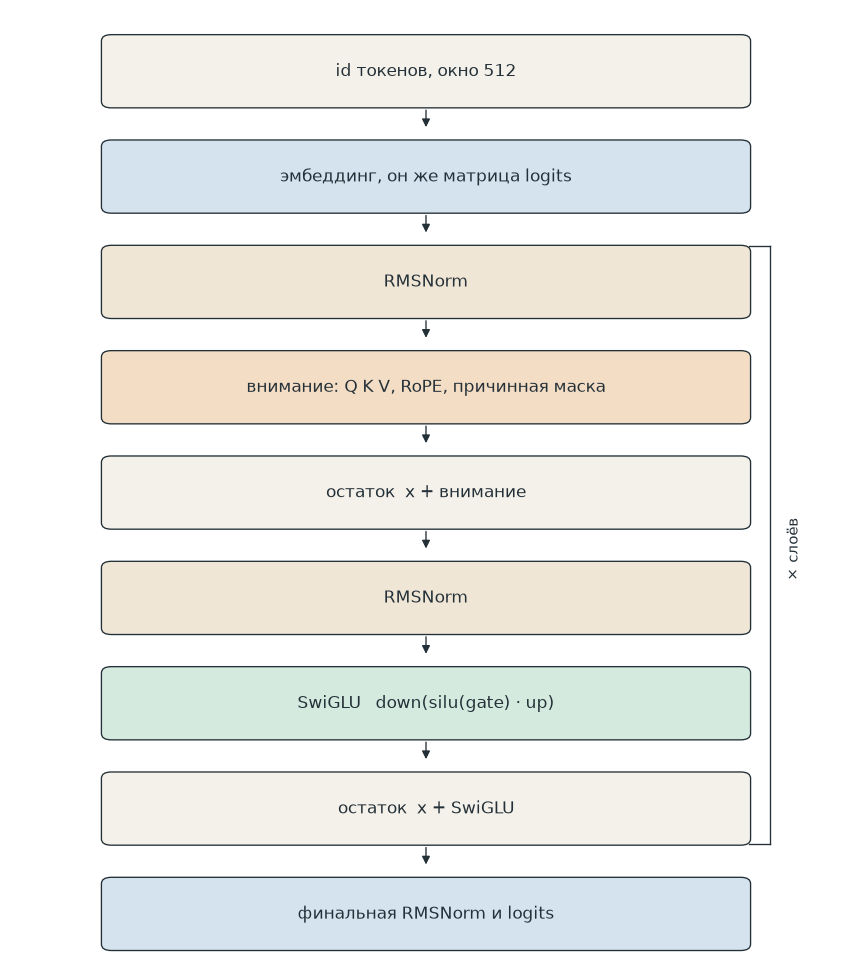

In [2]:
def block_diagram():
    fig, ax = plt.subplots(figsize=(7.2, 8.2))
    ax.set_xlim(0, 10)
    ax.set_ylim(0, 18)
    ax.axis("off")
    rows = [
        (16.2, PAPER, "id токенов, окно 512"),
        (14.2, "#d5e3ef", "эмбеддинг, он же матрица logits"),
        (12.2, "#efe6d6", "RMSNorm"),
        (10.2, "#f3ddc4", "внимание: Q K V, RoPE, причинная маска"),
        (8.2, PAPER, "остаток  x + внимание"),
        (6.2, "#efe6d6", "RMSNorm"),
        (4.2, "#d5eadf", "SwiGLU   down(silu(gate) · up)"),
        (2.2, PAPER, "остаток  x + SwiGLU"),
        (0.2, "#d5e3ef", "финальная RMSNorm и logits"),
    ]
    for y, color, text in rows:
        ax.add_patch(
            FancyBboxPatch(
                (1.1, y),
                7.8,
                1.35,
                boxstyle="round,pad=0.02,rounding_size=0.12",
                facecolor=color,
                edgecolor=INK,
                linewidth=0.8,
            )
        )
        ax.text(5.0, y + 0.67, text, ha="center", va="center", fontsize=10, color=INK)
    for y in (16.2, 14.2, 12.2, 10.2, 8.2, 6.2, 4.2, 2.2):
        ax.add_patch(
            FancyArrowPatch(
                (5.0, y),
                (5.0, y - 0.45),
                arrowstyle="-|>",
                mutation_scale=10,
                color=INK,
                linewidth=0.8,
            )
        )
    ax.plot([9.15, 9.15], [2.2, 13.55], color=INK, linewidth=0.8)
    ax.plot([9.15, 8.9], [13.55, 13.55], color=INK, linewidth=0.8)
    ax.plot([9.15, 8.9], [2.2, 2.2], color=INK, linewidth=0.8)
    ax.text(9.35, 7.8, "× слоёв", rotation=90, va="center", ha="left", fontsize=9, color=INK)
    fig.tight_layout()
    return fig


block_diagram()
plt.show()

## Что считает каждый блок

Один проход отвечает на вопрос: по окну из 512 уже увиденных id предсказать следующий. На модели 10.9M тензор внутри сети имеет форму `(батч, 512, 256)`. У 46.9M последняя ось 320, слоёв 30, голов 5. Формулы те же.

Ниже $d$ — ширина, $h$ — размер головы, $H$ — число голов, $d = H \cdot h$. У 10.9M это $256 = 4 \cdot 64$.

### Эмбеддинг

У каждого id есть строка матрицы $E$ размера $16000 \times d$. Вход позиции $t$ — эта строка:

$$x_t = E_{\mathrm{id}_t}$$

Та же матрица в конце превращает вектор слоя в логиты. Линейный слой без смещения считает $x W^\top$, а $W$ здесь равен $E$, поэтому логит словаря $v$ — скалярное произведение

$$\mathrm{logit}_v = x \cdot E_v$$

Обучаемых копий матрицы две нет: `lm_head.weight` и `embed.weight` — один и тот же тензор.

### RMSNorm

Для вектора $x \in \mathbb{R}^d$ со средним квадратом $\overline{x^2} = \frac{1}{d}\sum_i x_i^2$:

$$\mathrm{RMSNorm}(x) = \frac{x}{\sqrt{\overline{x^2} + \varepsilon}} \odot w$$

$\varepsilon = 10^{-5}$. Среднее не вычитается. Обучается только множитель $w$, по одному числу на канал, на старте все единицы. Считается отдельно для каждого токена.

### Внимание

Четыре матрицы $d \times d$, без смещений: $W_Q, W_K, W_V, W_O$.

$$q_t = x_t W_Q, \quad k_t = x_t W_K, \quad v_t = x_t W_V$$

Каждый из этих векторов режется на $H$ голов по $h$ чисел. Головы не смешиваются до самого $W_O$.

Позиция попадает в $q$ и $k$ поворотом RoPE, $v$ не крутится. Голова длины $h$ делится пополам. Пара координат $(a, b)$, где $a$ из первой половины, а $b$ из второй, на позиции $t$ и частоте $\omega$ переходит в

$$\begin{aligned}
a' &= a\cos(t\omega) - b\sin(t\omega) \\
b' &= a\sin(t\omega) + b\cos(t\omega)\end{aligned}$$

Частот $h/2$ штук. Для пары с номером $i = 0, 1, \ldots, h/2 - 1$

$$\omega_i = 10000^{-2i/h}$$

У головы 64 это $\omega_0 = 1$ и дальше до $10000^{-62/64}$. У соседнего токена угол больше на $\omega_i$, поэтому скалярное произведение $q$ и $k$ зависит от расстояния между позициями, а не от их абсолютных номеров по отдельности.

Дальше причинное внимание. Позиция $t$ смотрит на позиции $j \le t$:

$$\alpha_{tj} = \mathrm{softmax}_{j \le t}\left(\frac{q_t \cdot k_j}{\sqrt{h}}\right), \qquad y_t = \sum_{j \le t} \alpha_{tj}\, v_j$$

Для $j > t$ слагаемое в softmax не входит: `is_causal=True`. Делитель $\sqrt{h} = 8$ при голове 64. Головы склеиваются обратно в вектор длины $d$ и умножаются на $W_O$.

### Остаток

Слой не подменяет вектор, а прибавляет к нему поправку:

$$x \leftarrow x + \mathrm{Attention}(\mathrm{RMSNorm}(x))$$

$$x \leftarrow x + \mathrm{SwiGLU}(\mathrm{RMSNorm}(x))$$

Градиент по $x$ имеет слагаемое 1 от самого остатка, поэтому тридцать слоёв не обязаны пропускать сигнал только сквозь все матрицы подряд.

### SwiGLU

Три матрицы без смещений. Внутренняя ширина $d_{\mathrm{ff}} = \lceil 8d/3 \rceil$ вверх до кратного 256: 768 при $d = 256$ и 1024 при $d = 320$.

$$\mathrm{SwiGLU}(x) = W_{\mathrm{down}}\,\bigl(\mathrm{silu}(x W_{\mathrm{gate}}) \odot (x W_{\mathrm{up}})\bigr)$$

$$\mathrm{silu}(z) = z \,\sigma(z) = \frac{z}{1 + e^{-z}}$$

$W_{\mathrm{gate}}$ и $W_{\mathrm{up}}$ переводят $d \to d_{\mathrm{ff}}$, $W_{\mathrm{down}}$ возвращает $d_{\mathrm{ff}} \to d$. Поканальное произведение — это ворота: $\mathrm{silu}$ решает, насколько пропустить значение из `up`.

### Логиты и loss

После последнего слоя ещё одна RMSNorm, затем логиты через ту же $E$. Цель — окно, сдвинутое на один токен вправо. Кросс-энтропия по всем позициям:

$$\mathcal{L} = -\frac{1}{T}\sum_{t=0}^{T-1} \log p(y_t \mid x_{\le t}), \qquad p = \mathrm{softmax}(\mathrm{logits})$$

Отдельного «пустого» id нет. Ноль — это `<|endoftext|>`, его тоже нужно уметь предсказать.

### Старт весов

Все матрицы — независимые $\mathcal{N}(0, 0{,}02)$. Затем $W_O$ и $W_{\mathrm{down}}$ делятся на $\sqrt{2L}$: у 8 слоёв на 4, у 30 слоёв на $\sqrt{60} \approx 7{,}75$. Эти две матрицы как раз прибавляются к остатку на каждом слое, и без уменьшения сумма по глубине раздувается.

In [3]:
import torch

x = torch.tensor([1.0, -2.0, 2.0, 0.0])
variance = x.pow(2).mean()
normalized = x * torch.rsqrt(variance + 1e-5)
print("RMSNorm, веса = 1")
print(f"  средний квадрат {variance.item():.4f}")
print(f"  после нормы {normalized.tolist()}")

a, b = 0.6, -0.8
position, omega = 2.0, 1.0
angle = position * omega
cos, sin = math.cos(angle), math.sin(angle)
a2 = a * cos - b * sin
b2 = a * sin + b * cos
print("RoPE, пара (a, b) на позиции 2 при ω = 1")
print(f"  угол {angle:.4f} рад, cos {cos:.4f}, sin {sin:.4f}")
print(f"  (a', b') = ({a2:.4f}, {b2:.4f})")
print(f"  длина до {math.hypot(a, b):.4f}, после {math.hypot(a2, b2):.4f}")

RMSNorm, веса = 1
  средний квадрат 2.2500
  после нормы [0.6666651964187622, -1.3333303928375244, 1.3333303928375244, 0.0]
RoPE, пара (a, b) на позиции 2 при ω = 1
  угол 2.0000 рад, cos -0.4161, sin 0.9093
  (a', b') = (0.4777, 0.8785)
  длина до 1.0000, после 1.0000


Скобка справа — повторяемый слой: от первого RMSNorm до второго остатка. Эмбеддинг и финальная норма снаружи и у обеих моделей одни на сеть.

## Две формы

Словарь, размер головы, окно и связанный эмбеддинг общие. Меняются ширина и число слоёв. У 10.9M канал шире относительно глубины: 8 слоёв при ширине 256. У 46.9M тридцать слоёв при ширине 320, это нижняя из глубин, которую MobileLLM на сетях около 125M нашёл сильнее двенадцати слоёв.

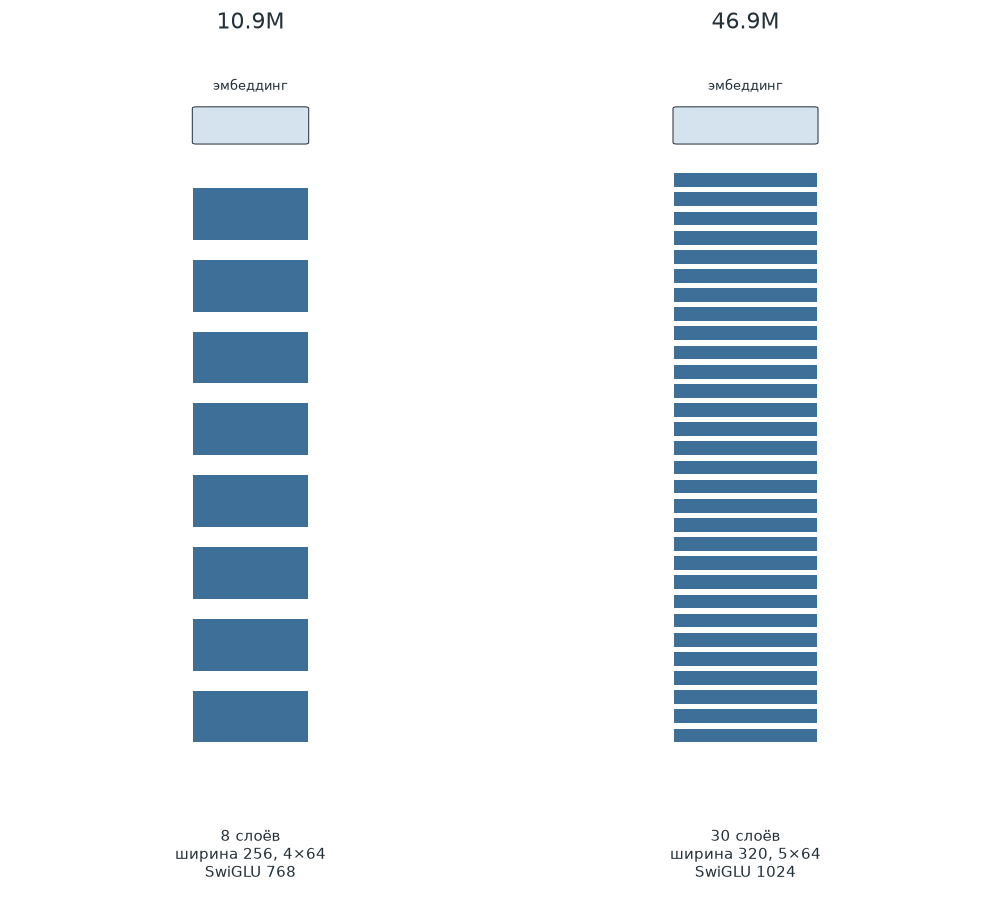

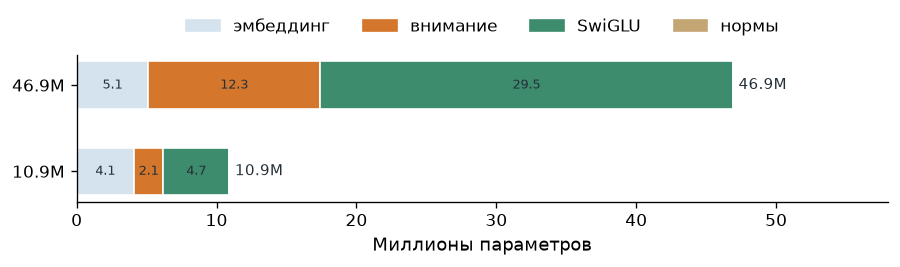

In [4]:
def describe(cfg: dict) -> dict:
    model = cfg["model"]
    hidden = int(model["hidden_size"])
    layers = int(model["n_layers"])
    vocab = int(model["vocab_size"])
    ffn = swiglu_width(hidden, int(model["swiglu_multiple_of"]))
    embed = vocab * hidden
    attention = layers * 4 * hidden * hidden
    swiglu = layers * 3 * hidden * ffn
    norms = (2 * layers + 1) * hidden
    total = embed + attention + swiglu + norms
    return {
        "hidden": hidden,
        "layers": layers,
        "heads": int(model["n_heads"]),
        "head_dim": hidden // int(model["n_heads"]),
        "ffn": ffn,
        "context": int(model["context"]),
        "vocab": vocab,
        "embed": embed,
        "attention": attention,
        "swiglu": swiglu,
        "norms": norms,
        "total": total,
        "tok_per_param": TRAIN_TOKENS / total,
        "residual_scale": math.sqrt(2 * layers),
    }


NETS = {
    "10.9M": describe(CFG_10),
    "46.9M": describe(CFG_50),
}
assert NETS["10.9M"]["total"] == 10_916_096
assert NETS["46.9M"]["total"] == 46_918_720
assert NETS["10.9M"]["ffn"] == 768
assert NETS["46.9M"]["ffn"] == 1024

fig, axes = plt.subplots(1, 2, figsize=(8.4, 7.6))
for ax, (name, spec) in zip(axes, NETS.items()):
    ax.set_xlim(0, 10)
    ax.set_ylim(0, 42)
    ax.axis("off")
    ax.set_title(name, color=INK, fontsize=13, pad=6)
    width = 2.4 * spec["hidden"] / 256
    x = 5 - width / 2
    ax.text(5, 39.3, "эмбеддинг", ha="center", va="bottom", fontsize=8, color=INK)
    ax.add_patch(
        FancyBboxPatch(
            (x, 36.8),
            width,
            1.8,
            boxstyle="round,pad=0.02,rounding_size=0.08",
            facecolor="#d5e3ef",
            edgecolor=INK,
            linewidth=0.6,
        )
    )
    span_top, span_bottom = 35.6, 7.2
    gap = (span_top - span_bottom) / spec["layers"]
    bar = gap * 0.72
    for index in range(spec["layers"]):
        y = span_top - (index + 1) * gap
        ax.add_patch(
            plt.Rectangle((x, y), width, bar, facecolor=BLUE, edgecolor="none")
        )
    ax.text(
        5,
        0.3,
        f"{spec['layers']} слоёв\nширина {spec['hidden']}, {spec['heads']}×{spec['head_dim']}\nSwiGLU {spec['ffn']}",
        ha="center",
        va="bottom",
        fontsize=9,
        color=INK,
    )
fig.tight_layout()
plt.show()

part_names = ["эмбеддинг", "внимание", "SwiGLU", "нормы"]
part_keys = ["embed", "attention", "swiglu", "norms"]
part_colors = ["#d5e3ef", ORANGE, GREEN, SAND]
fig, ax = plt.subplots(figsize=(7.6, 2.6))
for row, (name, spec) in enumerate(NETS.items()):
    left = 0.0
    for key, color, label in zip(part_keys, part_colors, part_names):
        width = spec[key] / 1e6
        ax.barh(name, width, left=left, color=color, edgecolor="white", height=0.55)
        if width >= 1.2:
            ax.text(left + width / 2, row, f"{width:.1f}", ha="center", va="center", fontsize=8, color=INK)
        left += width
    ax.text(left + 0.4, row, f"{spec['total'] / 1e6:.1f}M", va="center", fontsize=9, color=INK)
ax.set_xlabel("Миллионы параметров")
ax.set_xlim(0, 58)
handles = [
    plt.Rectangle((0, 0), 1, 1, color=color, label=label)
    for color, label in zip(part_colors, part_names)
]
ax.legend(handles=handles, frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, 1.35))
fig.tight_layout()
plt.show()

Полоска на башне — один слой. Ширина полоски пропорциональна ширине сети, высота башни — числу слоёв. Нормы на столбцах параметров почти не видны: у 10.9M их 4 352, у 46.9M — 19 520.

## Гиперпараметры

Режим обучения общий: тот же корпус, то же окно, тот же AdamW и то же WSD. Отличается форма сети.

In [5]:
def millions(value: int) -> str:
    return f"{value / 1e6:.2f}M".replace(".", ",")


shape = pd.DataFrame(
    {
        name: {
            "конфиг": path,
            "словарь": spec["vocab"],
            "ширина": spec["hidden"],
            "слои": spec["layers"],
            "головы": f"{spec['heads']} × {spec['head_dim']}",
            "SwiGLU": spec["ffn"],
            "контекст": spec["context"],
            "параметры": f"{spec['total']:,}".replace(",", " "),
            "эмбеддинг": millions(spec["embed"]),
            "тело": millions(spec["attention"] + spec["swiglu"] + spec["norms"]),
            "токенов на параметр": f"{spec['tok_per_param']:.1f}".replace(".", ","),
            "делитель остатка": f"{spec['residual_scale']:.2f}".replace(".", ","),
        }
        for (name, spec), path in zip(NETS.items(), ("configs/baseline.yaml", "configs/50m.yaml"))
    }
)
shape

,10.9M,46.9M
конфиг,configs/baseline.yaml,configs/50m.yaml
словарь,16000,16000
ширина,256,320
слои,8,30
головы,4 × 64,5 × 64
SwiGLU,768,1024
контекст,512,512
параметры,10 916 096,46 918 720
эмбеддинг,"4,10M","5,12M"
тело,"6,82M","41,80M"


In [6]:
train = CFG_10["train"]
schedule = CFG_10["schedule"]
tokens_per_step = int(train["batch_size"]) * int(train["grad_accum"]) * int(CFG_10["model"]["context"])
steps = int(train["max_steps"])
warm = int(steps * float(schedule["warmup_frac"]))
stable = int(steps * float(schedule["stable_frac"]))
decay = steps - warm - stable
shared = pd.Series(
    {
        "сид": train["seed"],
        "микробатч × накопление": f"{train['batch_size']} × {train['grad_accum']}",
        "токенов на шаг": f"{tokens_per_step:,}".replace(",", " "),
        "шаги одного прохода": f"{steps:,}".replace(",", " "),
        "AdamW β": str(tuple(train["betas"])),
        "weight decay": train["weight_decay"],
        "потолок градиента": train["grad_clip"],
        "тип весов": train["dtype"],
        "инициализация": "N(0, 0.02)",
        "расписание": schedule["name"],
        "пик lr": schedule["peak_lr"],
        "пол lr": schedule["min_lr"],
        "разогрев / полка / спад, шаги": f"{warm} / {stable} / {decay}",
        "форма спада": schedule["decay"],
        "RoPE θ": CFG_10["model"]["rope_theta"],
        "RMSNorm ε": CFG_10["model"]["rms_eps"],
    },
    name="обе модели",
)
shared.to_frame()

,обе модели
сид,22
микробатч × накопление,8 × 8
токенов на шаг,32 768
шаги одного прохода,18 955
AdamW β,"(0.9, 0.95)"
weight decay,0.1
потолок градиента,1.0
тип весов,float32
инициализация,"N(0, 0.02)"
расписание,wsd


Делитель остатка — `sqrt(2 × слои)`: у восьми слоёв 4, у тридцати около 7,75. Стартовые выходы внимания и SwiGLU у глубокой сети мельче.

## Кривые 10.9M

Короткий validation на графике — один и тот же кусок, 8 батчей, 32 768 токенов. Он всю дорогу ниже полного validation примерно на 0,3. Горизонтальные линии — полный validation и test из `summary.json`. С ними в конце блокнота сравнивается прогон 46.9M.

In [7]:
log = pd.read_json(RUN / "train_log.jsonl", lines=True)
summary = json.loads((RUN / "summary.json").read_text(encoding="utf-8"))
report = json.loads((RUN / "russian_eval.json").read_text(encoding="utf-8"))
log["train_smooth"] = log["train_loss"].rolling(51, center=True, min_periods=1).mean()
probe = log.dropna(subset=["val_loss"])
shelf_end = warm + stable - 1

outcome = pd.Series(
    {
        "параметры": f"{summary['parameters']:,}".replace(",", " "),
        "tokens seen": f"{summary['tokens_seen']:,}".replace(",", " "),
        "время обучения, мин": f"{summary['train_time_s'] / 60:.0f}",
        "пик памяти, МБ": f"{summary['peak_mem_mb']:.0f}",
        "полный validation": f"{summary['full_val_loss']:.3f}".replace(".", ","),
        "test": f"{summary['test_loss']:.3f}".replace(".", ","),
        "perplexity val / test": (
            f"{math.exp(summary['full_val_loss']):.1f} / {math.exp(summary['test_loss']):.1f}"
        ).replace(".", ","),
        "RuBLiMP": f"{report['rublimp']['accuracy']:.3f}".replace(".", ","),
        "LanguageTool, срабатывания / хвосты": (
            f"{report['languagetool']['n_matches']} / {report['languagetool']['n_continuations']}"
        ),
    },
    name="10.9M",
)
outcome.to_frame()

,10.9M
параметры,10 916 096
tokens seen,621 117 440
"время обучения, мин",94
"пик памяти, МБ",1901
полный validation,"3,594"
test,"3,615"
perplexity val / test,"36,4 / 37,2"
RuBLiMP,"0,787"
"LanguageTool, срабатывания / хвосты",1500 / 772


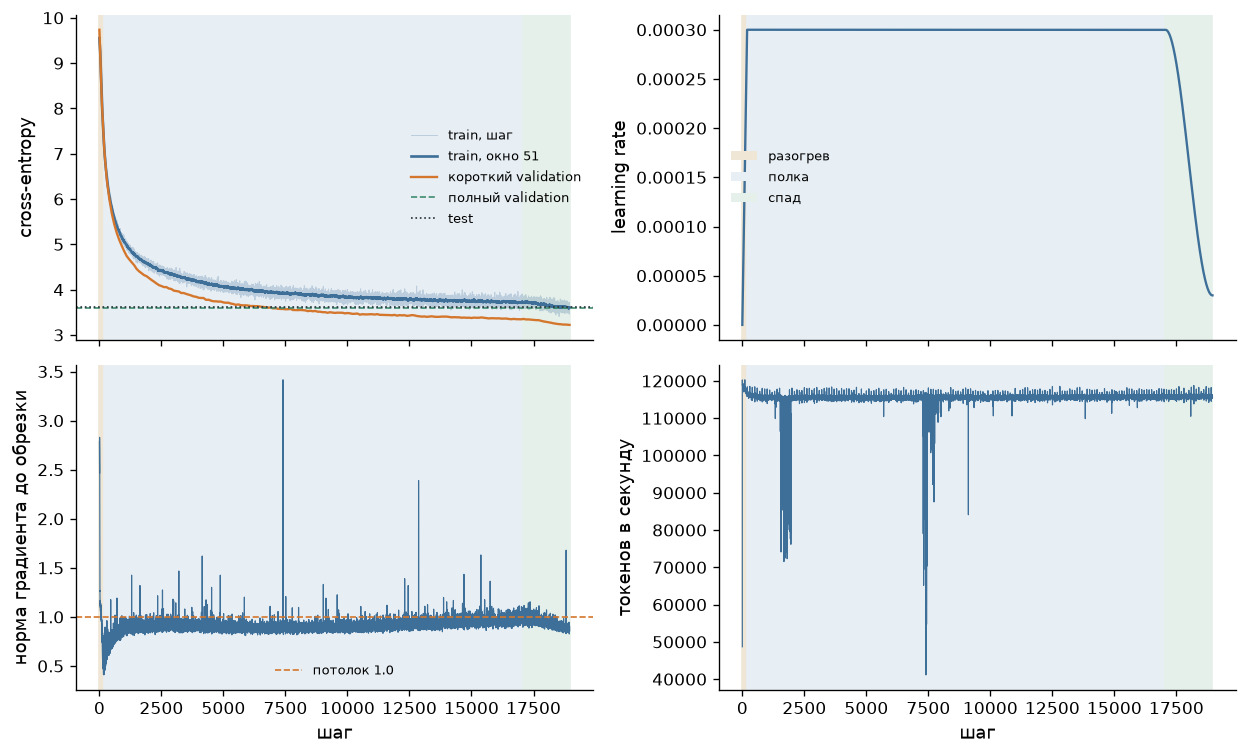

In [8]:
PHASES = (
        (0, warm, "#efe6d6", "разогрев"),
        (warm, shelf_end, "#e7eef4", "полка"),
        (shelf_end, int(log["step"].iloc[-1]), "#e5f0ea", "спад"),
    )


def shade(ax):
    for left, right, color, _label in PHASES:
        ax.axvspan(left, right, color=color, zorder=0)


fig, axes = plt.subplots(2, 2, figsize=(10.5, 6.4), sharex=True)
ax = axes[0, 0]
ax.plot(log["step"], log["train_loss"], color=BLUE, alpha=0.25, linewidth=0.6, label="train, шаг")
ax.plot(log["step"], log["train_smooth"], color=BLUE, linewidth=1.6, label="train, окно 51")
ax.plot(probe["step"], probe["val_loss"], color=ORANGE, linewidth=1.4, label="короткий validation")
ax.axhline(summary["full_val_loss"], color=GREEN, linestyle="--", linewidth=1, label="полный validation")
ax.axhline(summary["test_loss"], color=INK, linestyle=":", linewidth=1, label="test")
ax.set_ylabel("cross-entropy")
ax.legend(frameon=False, fontsize=8, loc="center right")
shade(ax)

ax = axes[0, 1]
ax.plot(log["step"], log["lr"], color=BLUE, linewidth=1.4)
ax.set_ylabel("learning rate")
shade(ax)
ax.legend(
    handles=[
        plt.Rectangle((0, 0), 1, 1, facecolor=color, edgecolor="none", label=label)
        for _left, _right, color, label in PHASES
    ],
    frameon=False,
    fontsize=8,
    loc="center left",
)

ax = axes[1, 0]
ax.plot(log["step"], log["grad_norm"], color=BLUE, linewidth=0.7)
ax.axhline(float(train["grad_clip"]), color=ORANGE, linestyle="--", linewidth=1, label="потолок 1.0")
ax.set_ylabel("норма градиента до обрезки")
ax.set_xlabel("шаг")
ax.legend(frameon=False, fontsize=8)
shade(ax)

ax = axes[1, 1]
tok_s = summary["tokens_per_step"] / log["step_time_s"]
ax.plot(log["step"], tok_s, color=BLUE, linewidth=0.7)
ax.set_ylabel("токенов в секунду")
ax.set_xlabel("шаг")
shade(ax)
fig.tight_layout()
plt.show()

Норма на графике — то, что вернул `clip_grad_norm_` до обрезки. Потолок 1.0 режет шаг, если норма выше. У этого прогона выше пяти она не поднималась, медиана около 0,9.

## Что модель печатает

Каждые 100 шагов — жадное продолжение четырёх промптов, 64 новых токена. Доля уникальных токенов в хвосте показывает, схлопнулся ли текст в повтор. Кириллица высока почти сразу: промпты русские, и ранний повтор тоже из русских букв.

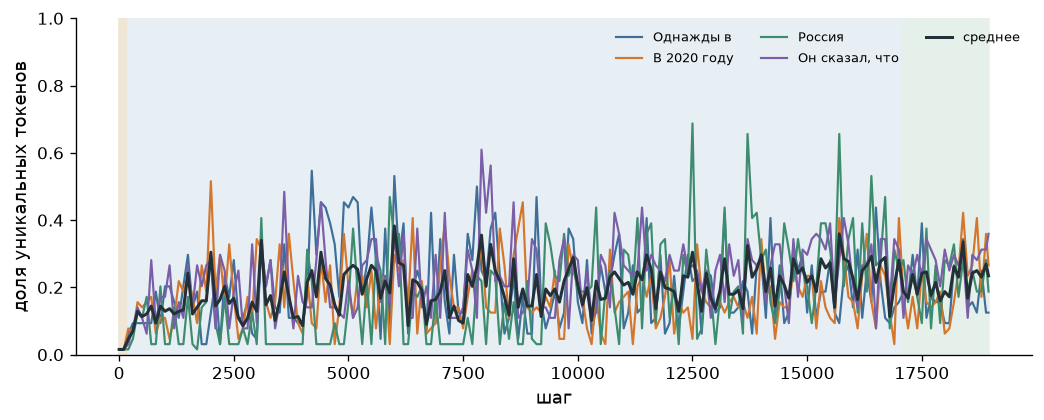

,step,prompt,уник.,продолжение
0,0,Однажды в,0.02,в в в в в в в в в в в в в в в в в в в в в в в ...
1,0,В 2020 году,0.02,году году году году году году году году году г...
2,0,Россия,0.02,РоссияРоссияРоссияРоссияРоссияРоссияРоссияРосс...
3,0,"Он сказал, что",0.02,что что что что что что что что что что что чт...
4,500,Однажды в,0.09,"том, что в том числе и в том числе и в том чис..."
5,500,В 2020 году,0.14,"в России. В России, в том числе и в России, в ..."
6,500,Россия,0.11,", что это не только, но и не только, но и не т..."
7,500,"Он сказал, что",0.11,"он не было, но не было, что я не было, что я н..."
8,2000,Однажды в,0.12,день. В день рождения ребенка в день рождения ...
9,2000,В 2020 году,0.52,"в России будет зависеть от того, насколько вы ..."


In [9]:
gen = pd.read_json(RUN / "generations.jsonl", lines=True)
greedy = gen[(gen["phase"] == "train") & (gen["temperature"] == 0.0)].copy()
prompt_colors = {
    "Однажды в": BLUE,
    "В 2020 году": ORANGE,
    "Россия": GREEN,
    "Он сказал, что": "#7a5ea7",
}

fig, ax = plt.subplots(figsize=(8.8, 3.6))
for prompt, color in prompt_colors.items():
    part = greedy[greedy["prompt"] == prompt]
    ax.plot(part["step"], part["unique_frac"], color=color, linewidth=1.3, label=prompt)
mean_unique = greedy.groupby("step")["unique_frac"].mean()
ax.plot(mean_unique.index, mean_unique.values, color=INK, linewidth=1.8, label="среднее")
ax.set_ylabel("доля уникальных токенов")
ax.set_xlabel("шаг")
ax.set_ylim(0, 1)
ax.legend(frameon=False, ncol=3, fontsize=8, loc="upper right")
shade(ax)
fig.tight_layout()
plt.show()


def shorten(text: str, limit: int = 110) -> str:
    flat = " ".join(text.split())
    if len(flat) <= limit:
        return flat
    return flat[: limit - 1] + "…"


shown_steps = [0, 500, 2_000, 5_000, 18_954]
preview = greedy[greedy["step"].isin(shown_steps)].copy()
preview["продолжение"] = preview["continuation"].map(shorten)
preview["уник."] = preview["unique_frac"].map(lambda value: f"{value:.2f}")
preview[["step", "prompt", "уник.", "продолжение"]].reset_index(drop=True)

Жадный декодер к концу снова зацикливается, поэтому доля уникальных токенов на финале низкая. При температуре 0,8 хвост длиннее и разнообразнее. Это уже лист `final` в том же файле, по 128 новых токенов.

In [10]:
sampled = gen[(gen["phase"] == "final") & (gen["temperature"] == 0.8)].copy()
sampled["продолжение"] = sampled["continuation"].map(lambda text: shorten(text, 160))
sampled["уник."] = sampled["unique_frac"].map(lambda value: f"{value:.2f}")
sampled["кирилл."] = sampled["cyrillic_frac"].map(lambda value: f"{value:.2f}")
sampled[["prompt", "уник.", "кирилл.", "продолжение"]].reset_index(drop=True)

,prompt,уник.,кирилл.,продолжение
0,Однажды в,0.66,1.00,"ее дом, я подумала, как проделал из нее бленде..."
1,В 2020 году,0.83,1.00,"идет плановый ремонт дома, чтобы центральный и..."
2,Россия,0.70,1.00,- Значения взаимопонимания - Бесчисленное толк...
3,"Он сказал, что",0.75,0.97,"побеждал в деньгах, и что из-за войны с Дженни..."


## Русский

RuBLiMP: 45 тысяч пар, 45 конфигураций. Пара засчитана, если средняя кросс-энтропия нашего BPE ниже у грамматичной фразы. Случайный уровень 0,50. Фраз длиннее окна 512 в этом прогоне не было.

Уровни на правом графике собраны из сумм в отчёте. Morphology — словообразование и словоизменение, 6 000 пар. Semantics — аргументная структура, вид и время, 11 000. Остальные явления — Syntax, 28 000.

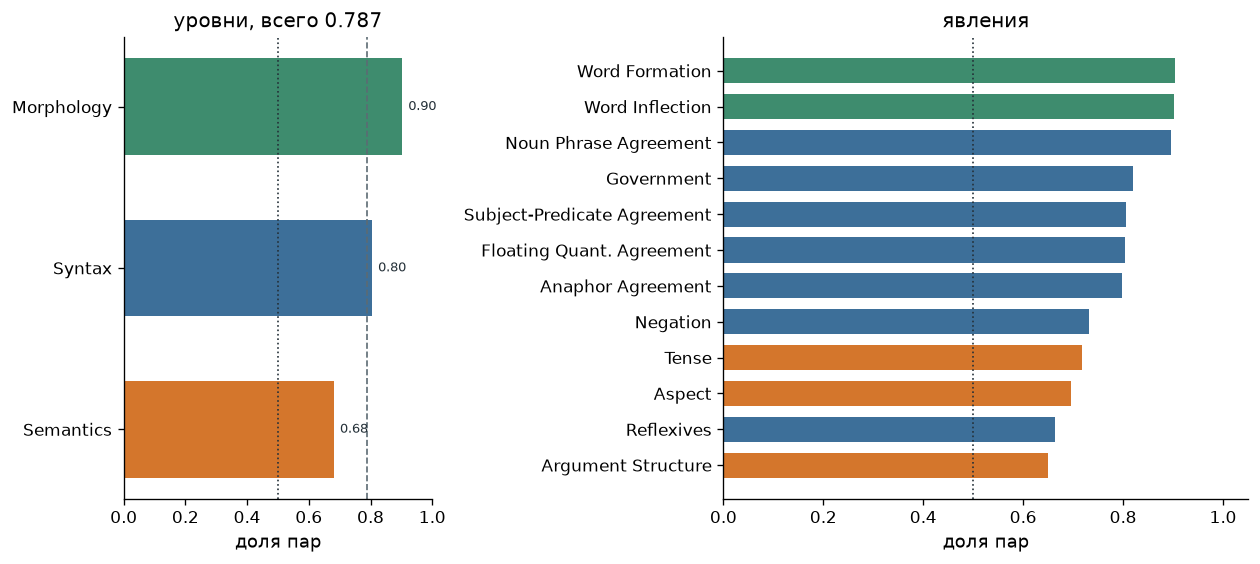

In [11]:
rublimp = report["rublimp"]
level = (
    pd.DataFrame(rublimp["by_level"])
    .T.reset_index(names="уровень")
    .sort_values("accuracy", ascending=True)
)
phenomenon_level = {
    "Word Formation": "Morphology",
    "Word Inflection": "Morphology",
    "Argument Structure": "Semantics",
    "Aspect": "Semantics",
    "Tense": "Semantics",
}
phenomenon = pd.DataFrame(rublimp["by_phenomenon"]).T.reset_index(names="явление")
phenomenon["уровень"] = phenomenon["явление"].map(lambda name: phenomenon_level.get(name, "Syntax"))
phenomenon = phenomenon.sort_values("accuracy", ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(10.6, 4.8), gridspec_kw={"width_ratios": [1, 1.7]})
ax = axes[0]
ax.barh(
    level["уровень"],
    level["accuracy"],
    color=[LEVEL_COLOR[name] for name in level["уровень"]],
    height=0.6,
)
ax.axvline(0.5, color=INK, linestyle=":", linewidth=1)
ax.axvline(rublimp["accuracy"], color="#5c6b73", linestyle="--", linewidth=1)
ax.set_xlim(0, 1)
ax.set_xlabel("доля пар")
for y, row in enumerate(level.itertuples(index=False)):
    ax.text(row.accuracy + 0.02, y, f"{row.accuracy:.2f}", va="center", fontsize=8, color=INK)
ax.set_title(f"уровни, всего {rublimp['accuracy']:.3f}")

ax = axes[1]
ax.barh(
    phenomenon["явление"],
    phenomenon["accuracy"],
    color=[LEVEL_COLOR[name] for name in phenomenon["уровень"]],
    height=0.7,
)
ax.axvline(0.5, color=INK, linestyle=":", linewidth=1)
ax.set_xlim(0, 1.05)
ax.set_xlabel("доля пар")
ax.set_title("явления")
fig.tight_layout()
plt.show()

Пунктир на левом графике — случайный уровень, штрих — общая доля 0,787. Выше всего словоизменение и словообразование, около 0,90. Ниже аргументная структура и рефлексивы, около 0,65.

LanguageTool посчитал русские правила по полю `continuation` всего `generations.jsonl`: 1 500 срабатываний на 772 хвостах, около 1,9 на хвост. В эти 772 входят и ранние жадные повторы, и финальные сэмплы с температурой 0,8. Отдельной разбивки по шагу или по правилу в отчёте нет, поэтому кривую LanguageTool по ходу обучения отсюда не построить.

## Кривые 46.9M

Тот же режим, что у 10.9M: один проход, 18 955 шагов, окно 512, 32 768 токенов на шаг. Короткий validation — те же 8 батчей и тот же кусок файла. Горизонтальные линии — полный validation и test.


In [12]:
log50 = pd.read_json(RUN_50 / "train_log.jsonl", lines=True)
summary50 = json.loads((RUN_50 / "summary.json").read_text(encoding="utf-8"))
report50 = json.loads((RUN_50 / "russian_eval.json").read_text(encoding="utf-8"))
log50["train_smooth"] = log50["train_loss"].rolling(51, center=True, min_periods=1).mean()
probe50 = log50.dropna(subset=["val_loss"])

outcome50 = pd.Series(
    {
        "параметры": f"{summary50['parameters']:,}".replace(",", " "),
        "tokens seen": f"{summary50['tokens_seen']:,}".replace(",", " "),
        "время обучения, мин": f"{summary50['train_time_s'] / 60:.0f}",
        "пик памяти, МБ": f"{summary50['peak_mem_mb']:.0f}",
        "полный validation": f"{summary50['full_val_loss']:.3f}".replace(".", ","),
        "test": f"{summary50['test_loss']:.3f}".replace(".", ","),
        "perplexity val / test": (
            f"{math.exp(summary50['full_val_loss']):.1f} / {math.exp(summary50['test_loss']):.1f}"
        ).replace(".", ","),
        "RuBLiMP": f"{report50['rublimp']['accuracy']:.3f}".replace(".", ","),
        "LanguageTool, срабатывания / хвосты": (
            f"{report50['languagetool']['n_matches']} / {report50['languagetool']['n_continuations']}"
        ),
    },
    name="46.9M",
)
outcome50.to_frame()


,46.9M
параметры,46 918 720
tokens seen,621 117 440
"время обучения, мин",399
"пик памяти, МБ",5245
полный validation,"3,243"
test,"3,262"
perplexity val / test,"25,6 / 26,1"
RuBLiMP,"0,827"
"LanguageTool, срабатывания / хвосты",1093 / 772


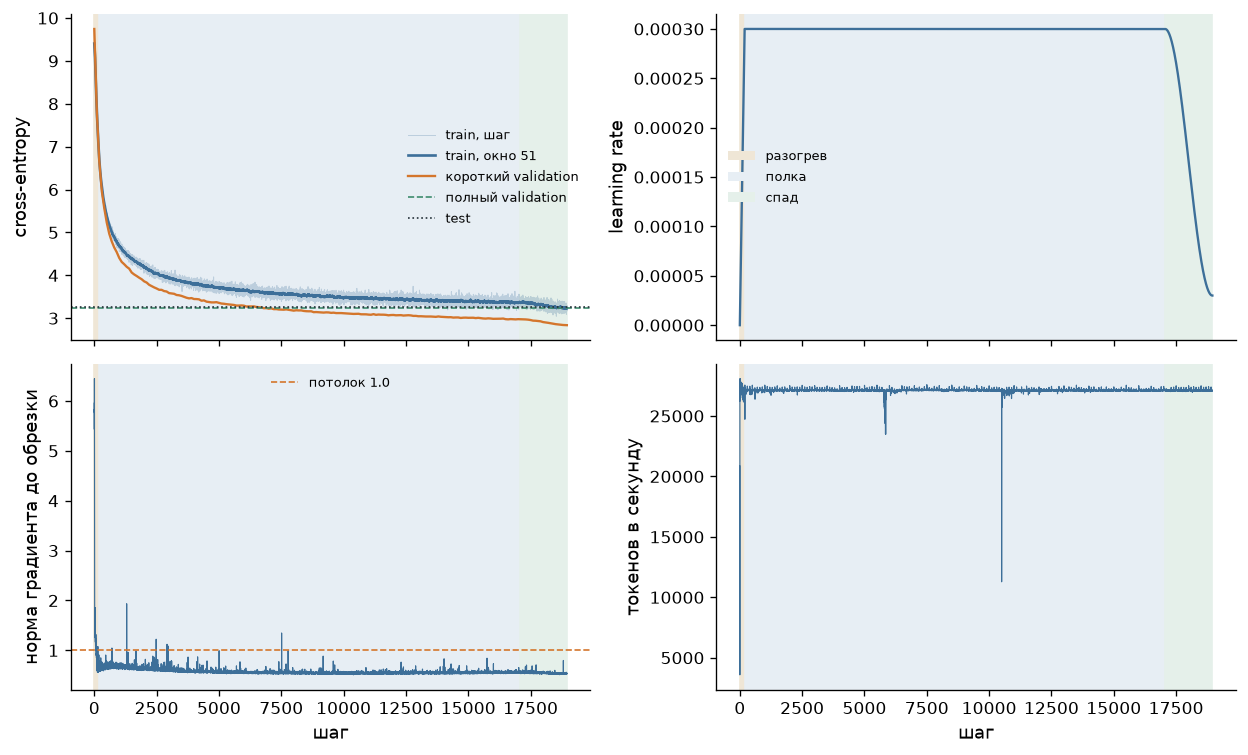

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(10.5, 6.4), sharex=True)
ax = axes[0, 0]
ax.plot(log50["step"], log50["train_loss"], color=BLUE, alpha=0.25, linewidth=0.6, label="train, шаг")
ax.plot(log50["step"], log50["train_smooth"], color=BLUE, linewidth=1.6, label="train, окно 51")
ax.plot(probe50["step"], probe50["val_loss"], color=ORANGE, linewidth=1.4, label="короткий validation")
ax.axhline(summary50["full_val_loss"], color=GREEN, linestyle="--", linewidth=1, label="полный validation")
ax.axhline(summary50["test_loss"], color=INK, linestyle=":", linewidth=1, label="test")
ax.set_ylabel("cross-entropy")
ax.legend(frameon=False, fontsize=8, loc="center right")
shade(ax)

ax = axes[0, 1]
ax.plot(log50["step"], log50["lr"], color=BLUE, linewidth=1.4)
ax.set_ylabel("learning rate")
shade(ax)
ax.legend(
    handles=[
        plt.Rectangle((0, 0), 1, 1, facecolor=color, edgecolor="none", label=label)
        for _left, _right, color, label in PHASES
    ],
    frameon=False,
    fontsize=8,
    loc="center left",
)

ax = axes[1, 0]
ax.plot(log50["step"], log50["grad_norm"], color=BLUE, linewidth=0.7)
ax.axhline(float(CFG_50["train"]["grad_clip"]), color=ORANGE, linestyle="--", linewidth=1, label="потолок 1.0")
ax.set_ylabel("норма градиента до обрезки")
ax.set_xlabel("шаг")
ax.legend(frameon=False, fontsize=8)
shade(ax)

ax = axes[1, 1]
tok_s50 = summary50["tokens_per_step"] / log50["step_time_s"]
ax.plot(log50["step"], tok_s50, color=BLUE, linewidth=0.7)
ax.set_ylabel("токенов в секунду")
ax.set_xlabel("шаг")
shade(ax)
fig.tight_layout()
plt.show()


Потолок 1.0 здесь уже режет шаг. Медиана нормы около 0,55, на старте она доходит до 6,4, выше единицы — на 83 шагах. У 10.9M выше пяти норма не поднималась.

## Что печатает 46.9M

Те же четыре промпта, каждые 100 шагов, жадно, 64 новых токена.


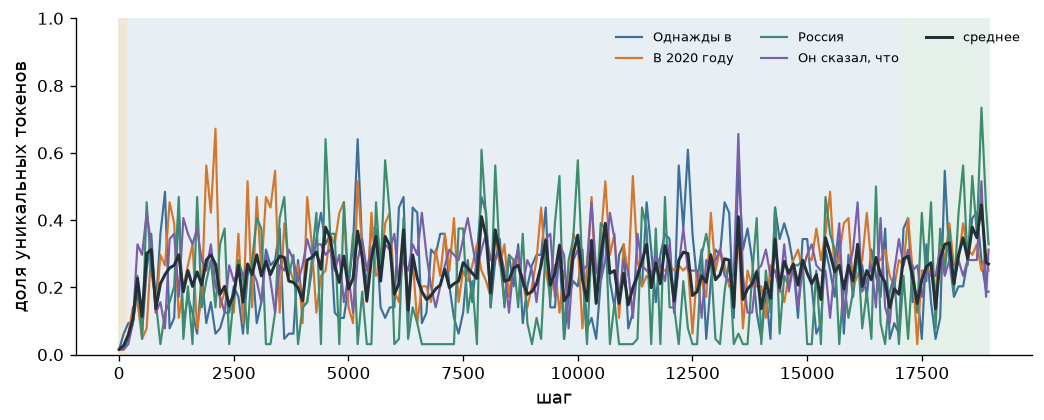

,step,prompt,уник.,продолжение
0,0,Однажды в,0.02,в в в в в в в в в в в в в в в в в в в в в в в ...
1,0,В 2020 году,0.02,урав урав урав урав урав урав урав урав урав у...
2,0,Россия,0.02,черного черного черного черного черного черног...
3,0,"Он сказал, что",0.02,0000000000000000000000000000000000000000000000...
4,500,Однажды в,0.06,России. - - - - - - - - - - - - - - - - - - - ...
5,500,В 2020 году,0.05,. - - - - - - - - - - - - - - - - - - - - - - ...
6,500,Россия,0.05,. - - - - - - - - - - - - - - - - - - - - - - ...
7,500,"Он сказал, что",0.30,"в России не будет не только в том, что в этом ..."
8,2000,Однажды в,0.16,день. - В течение месяца в день можно будет в ...
9,2000,В 2020 году,0.42,"в России было зарегистрировано более 1,5 млн ч..."


In [14]:
gen50 = pd.read_json(RUN_50 / "generations.jsonl", lines=True)
greedy50 = gen50[(gen50["phase"] == "train") & (gen50["temperature"] == 0.0)].copy()

fig, ax = plt.subplots(figsize=(8.8, 3.6))
for prompt, color in prompt_colors.items():
    part = greedy50[greedy50["prompt"] == prompt]
    ax.plot(part["step"], part["unique_frac"], color=color, linewidth=1.3, label=prompt)
mean_unique50 = greedy50.groupby("step")["unique_frac"].mean()
ax.plot(mean_unique50.index, mean_unique50.values, color=INK, linewidth=1.8, label="среднее")
ax.set_ylabel("доля уникальных токенов")
ax.set_xlabel("шаг")
ax.set_ylim(0, 1)
ax.legend(frameon=False, ncol=3, fontsize=8, loc="upper right")
shade(ax)
fig.tight_layout()
plt.show()

preview50 = greedy50[greedy50["step"].isin(shown_steps)].copy()
preview50["продолжение"] = preview50["continuation"].map(shorten)
preview50["уник."] = preview50["unique_frac"].map(lambda value: f"{value:.2f}")
preview50[["step", "prompt", "уник.", "продолжение"]].reset_index(drop=True)


Жадный декодер к концу снова зацикливается. Лист `final` — те же промпты, 128 новых токенов, температура 0,8 и сид 22.


In [15]:
sampled50 = gen50[(gen50["phase"] == "final") & (gen50["temperature"] == 0.8)].copy()
sampled50["продолжение"] = sampled50["continuation"].map(lambda text: shorten(text, 160))
sampled50["уник."] = sampled50["unique_frac"].map(lambda value: f"{value:.2f}")
sampled50["кирилл."] = sampled50["cyrillic_frac"].map(lambda value: f"{value:.2f}")
sampled50[["prompt", "уник.", "кирилл.", "продолжение"]].reset_index(drop=True)


,prompt,уник.,кирилл.,продолжение
0,Однажды в,0.71,1.00,ее жизни случилась ночь. Изгнан из будущего. П...
1,В 2020 году,0.70,1.00,"идет серьезная торговля, чтобы подстраховаться..."
2,Россия,0.55,1.00,- Секс знакомства в Уральске - Сайт знакомств ...
3,"Он сказал, что",0.73,1.00,побил и теперь отпустил его на задний план. Он...


## Русский, 46.9M

Та же оценка: 45 тысяч пар RuBLiMP, пропусков из-за длины нет. Цвета уровней те же, что у 10.9M.


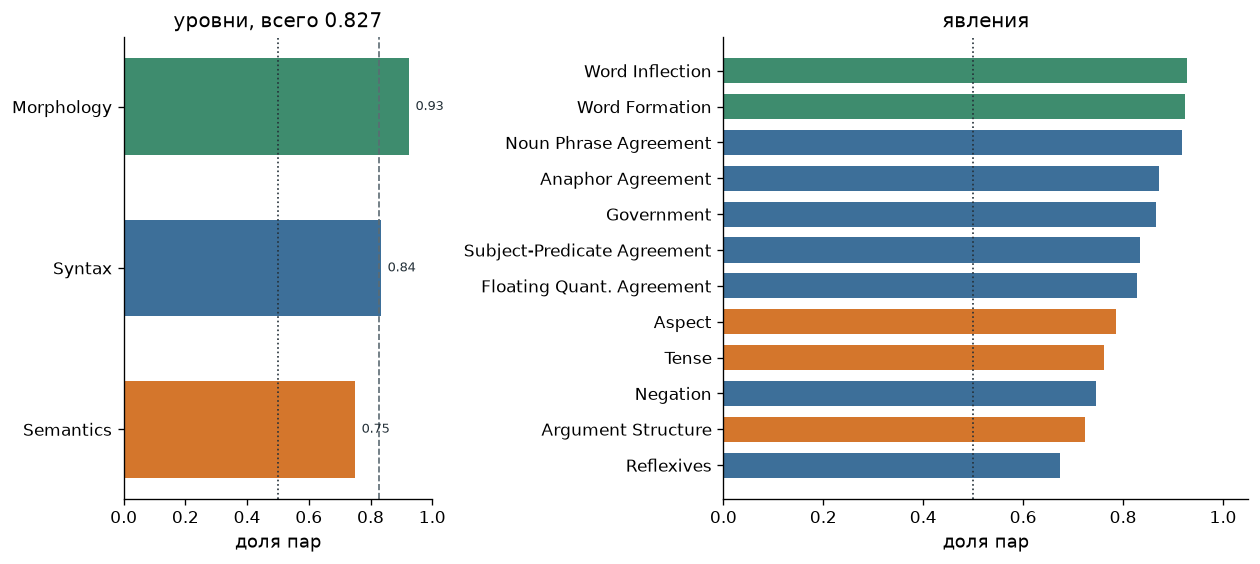

In [16]:
rublimp50 = report50["rublimp"]
level50 = (
    pd.DataFrame(rublimp50["by_level"])
    .T.reset_index(names="уровень")
    .sort_values("accuracy", ascending=True)
)
phenomenon50 = pd.DataFrame(rublimp50["by_phenomenon"]).T.reset_index(names="явление")
phenomenon50["уровень"] = phenomenon50["явление"].map(lambda name: phenomenon_level.get(name, "Syntax"))
phenomenon50 = phenomenon50.sort_values("accuracy", ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(10.6, 4.8), gridspec_kw={"width_ratios": [1, 1.7]})
ax = axes[0]
ax.barh(
    level50["уровень"],
    level50["accuracy"],
    color=[LEVEL_COLOR[name] for name in level50["уровень"]],
    height=0.6,
)
ax.axvline(0.5, color=INK, linestyle=":", linewidth=1)
ax.axvline(rublimp50["accuracy"], color="#5c6b73", linestyle="--", linewidth=1)
ax.set_xlim(0, 1)
ax.set_xlabel("доля пар")
for y, row in enumerate(level50.itertuples(index=False)):
    ax.text(row.accuracy + 0.02, y, f"{row.accuracy:.2f}", va="center", fontsize=8, color=INK)
ax.set_title(f"уровни, всего {rublimp50['accuracy']:.3f}")

ax = axes[1]
ax.barh(
    phenomenon50["явление"],
    phenomenon50["accuracy"],
    color=[LEVEL_COLOR[name] for name in phenomenon50["уровень"]],
    height=0.7,
)
ax.axvline(0.5, color=INK, linestyle=":", linewidth=1)
ax.set_xlim(0, 1.05)
ax.set_xlabel("доля пар")
ax.set_title("явления")
fig.tight_layout()
plt.show()


Пунктир — случайный уровень 0,50, штрих — общая доля 0,827. Morphology 0,926, Syntax 0,835, Semantics 0,751. LanguageTool: 1 093 срабатывания на тех же 772 хвостах, около 1,4 на хвост.

## Сравнение

Один train, одно окно 512, один проход. Синий — 10.9M, оранжевый — 46.9M. На графике loss сплошная линия — сглаженный train, пунктир — полный validation.


,10.9M,46.9M
параметры,10 916 096,46 918 720
tokens seen,621 117 440,621 117 440
"время обучения, мин",94,399
"пик памяти, МБ",1901,5245
полный validation,"3,594","3,243"
test,"3,615","3,262"
perplexity val / test,"36,4 / 37,2","25,6 / 26,1"
RuBLiMP,"0,787","0,827"
"LanguageTool, срабатывания / хвосты",1500 / 772,1093 / 772


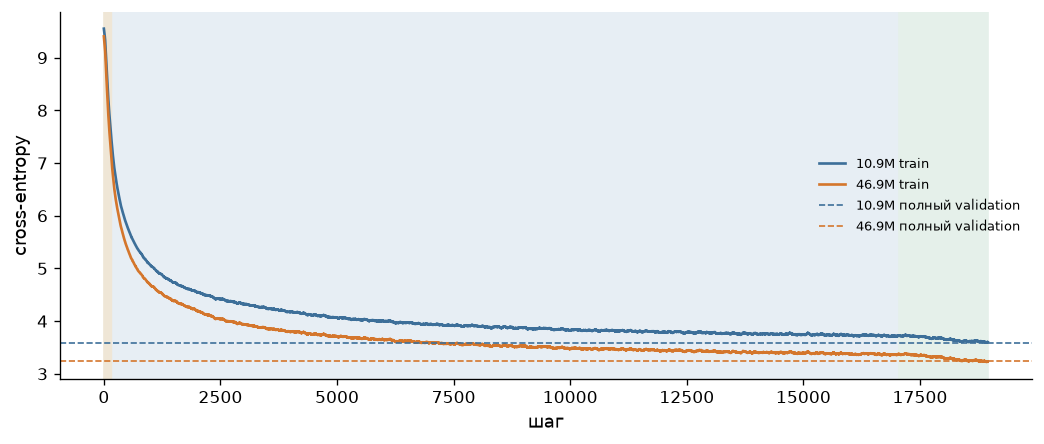

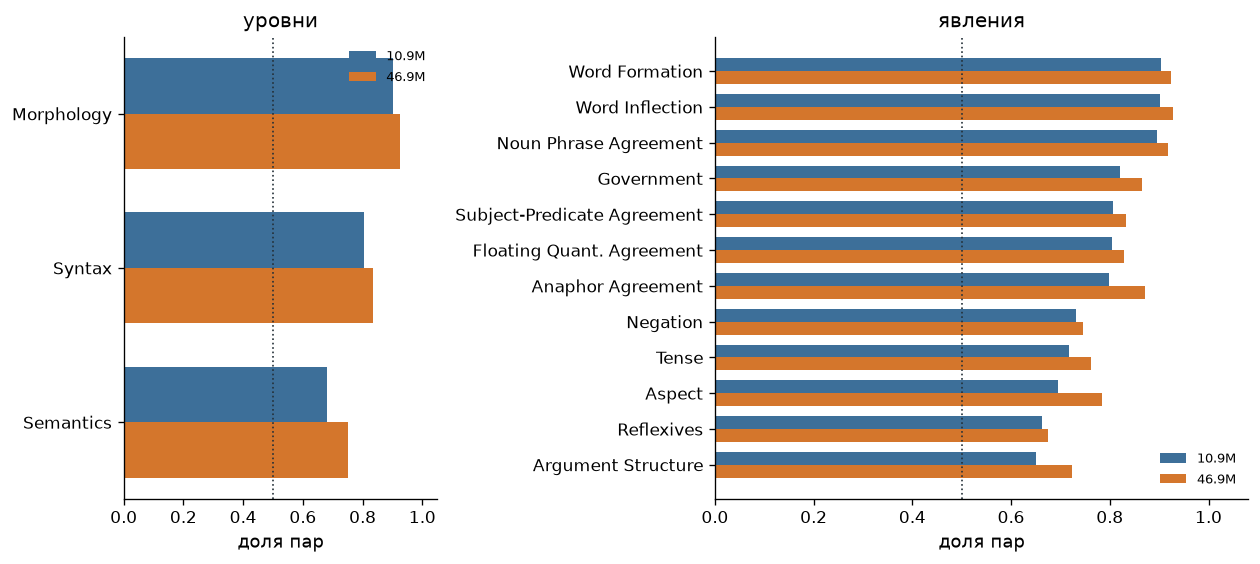

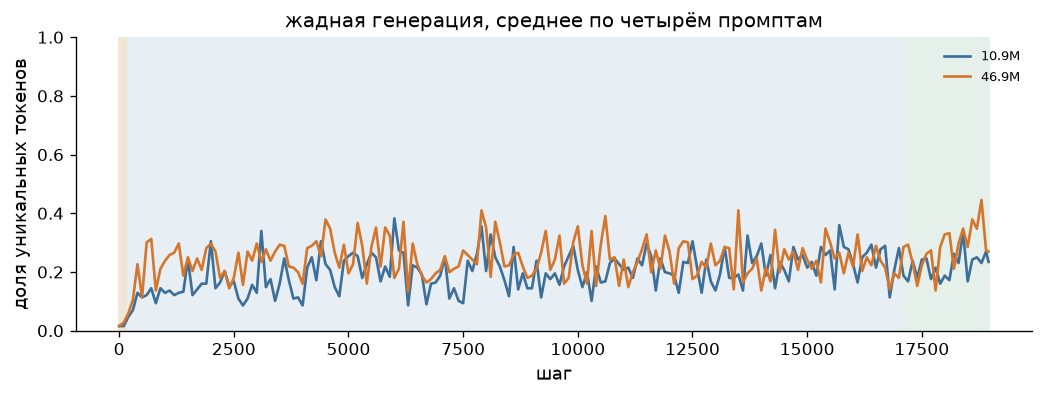

In [17]:
both = pd.concat([outcome.rename("10.9M"), outcome50.rename("46.9M")], axis=1)
display(both)

fig, ax = plt.subplots(figsize=(8.8, 3.8))
ax.plot(log["step"], log["train_smooth"], color=BLUE, linewidth=1.6, label="10.9M train")
ax.plot(log50["step"], log50["train_smooth"], color=ORANGE, linewidth=1.6, label="46.9M train")
ax.axhline(summary["full_val_loss"], color=BLUE, linestyle="--", linewidth=1, label="10.9M полный validation")
ax.axhline(summary50["full_val_loss"], color=ORANGE, linestyle="--", linewidth=1, label="46.9M полный validation")
ax.set_ylabel("cross-entropy")
ax.set_xlabel("шаг")
ax.legend(frameon=False, fontsize=8, loc="center right")
shade(ax)
fig.tight_layout()
plt.show()

order = level.sort_values("accuracy")["уровень"].tolist()
acc10 = level.set_index("уровень").loc[order, "accuracy"]
acc50 = level50.set_index("уровень").loc[order, "accuracy"]
phen_order = phenomenon.sort_values("accuracy")["явление"].tolist()
phen10 = phenomenon.set_index("явление").loc[phen_order, "accuracy"]
phen50 = phenomenon50.set_index("явление").loc[phen_order, "accuracy"]

fig, axes = plt.subplots(1, 2, figsize=(10.6, 4.8), gridspec_kw={"width_ratios": [1, 1.7]})
y = np.arange(len(order))
axes[0].barh(y + 0.18, acc10, height=0.36, color=BLUE, label="10.9M")
axes[0].barh(y - 0.18, acc50, height=0.36, color=ORANGE, label="46.9M")
axes[0].set_yticks(y)
axes[0].set_yticklabels(order)
axes[0].axvline(0.5, color=INK, linestyle=":", linewidth=1)
axes[0].set_xlim(0, 1.05)
axes[0].set_xlabel("доля пар")
axes[0].set_title("уровни")
axes[0].legend(frameon=False, fontsize=8)

y = np.arange(len(phen_order))
axes[1].barh(y + 0.18, phen10, height=0.36, color=BLUE, label="10.9M")
axes[1].barh(y - 0.18, phen50, height=0.36, color=ORANGE, label="46.9M")
axes[1].set_yticks(y)
axes[1].set_yticklabels(phen_order)
axes[1].axvline(0.5, color=INK, linestyle=":", linewidth=1)
axes[1].set_xlim(0, 1.08)
axes[1].set_xlabel("доля пар")
axes[1].set_title("явления")
axes[1].legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

mean10 = greedy.groupby("step")["unique_frac"].mean()
fig, ax = plt.subplots(figsize=(8.8, 3.4))
ax.plot(mean10.index, mean10.values, color=BLUE, linewidth=1.6, label="10.9M")
ax.plot(mean_unique50.index, mean_unique50.values, color=ORANGE, linewidth=1.6, label="46.9M")
ax.set_ylabel("доля уникальных токенов")
ax.set_xlabel("шаг")
ax.set_ylim(0, 1)
ax.set_title("жадная генерация, среднее по четырём промптам")
ax.legend(frameon=False, fontsize=8)
shade(ax)
fig.tight_layout()
plt.show()


46.9M ниже по полному validation и test: 3,243 и 3,262 против 3,594 и 3,615. Perplexity 25,6 / 26,1 против 36,4 / 37,2. RuBLiMP 0,827 против 0,787, выше на всех трёх уровнях и на всех двенадцати явлениях. Крупнее всего сдвиг у Aspect, Argument Structure и Anaphor Agreement. LanguageTool на тех же 772 хвостах: 1 093 срабатывания против 1 500.

Жадная доля уникальных токенов к концу снова падает у обеих сетей. При температуре 0,8 хвосты длиннее, связного абзаца нет ни там, ни там.
